First five rows:
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  texture_worst  perimeter_worst  area_

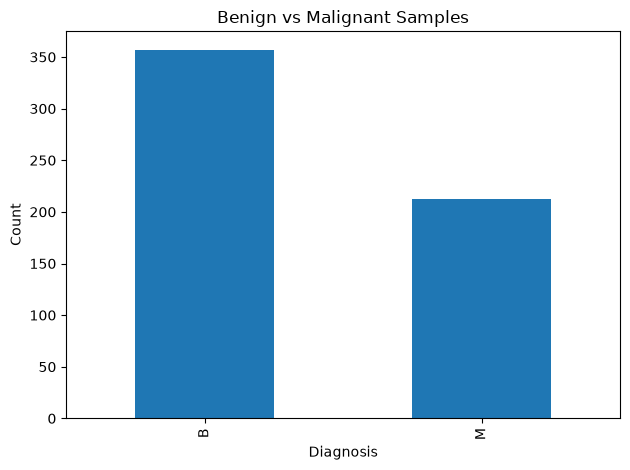


Feature shape: (569, 30)
Target shape: (569,)

Numerical features: ['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst']

Categorical features: []

Training samples: 455
Testing samples: 114

Best Random Forest parameters:
{'classifier__max_depth': None, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 100}

MODEL: Decision Tree
Accuracy : 0.9298
Precision: 0.9048
Recall   : 0.9048
F1-score : 0.9048
ROC-AUC  : 0.9246

Confusion Matrix:
[[68  4]
 [ 4 38]]

Classification Report:
         

In [2]:
# ============================================================
# BREAST CANCER CLASSIFICATION - COMPLETE ML PIPELINE
# Dataset: Kaggle Breast Cancer Wisconsin (Diagnostic)
# Models: Decision Tree, Random Forest, AdaBoost, Stacking
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    StackingClassifier
)
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)


# ------------------------------------------------------------
# 1. LOAD THE DATASET
# ------------------------------------------------------------

df = pd.read_csv("data.csv")

print("First five rows:")
print(df.head())

print("\nDataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())


# ------------------------------------------------------------
# 2. EXPLORATORY DATA ANALYSIS (EDA)
# ------------------------------------------------------------

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
print(df.describe())

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

# Identify the target column.
target_col = "diagnosis"

if target_col not in df.columns:
    raise ValueError("The CSV must contain a 'diagnosis' column.")

print("\nTarget class distribution:")
print(df[target_col].value_counts())

df[target_col].value_counts().plot(kind="bar")
plt.title("Benign vs Malignant Samples")
plt.xlabel("Diagnosis")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. DATA PREPROCESSING AND TARGET SELECTION
# ------------------------------------------------------------

# Remove columns that contain no useful data.
df = df.dropna(axis=1, how="all")

# Remove rows with a missing target.
df = df.dropna(subset=[target_col])

# Convert diagnosis into numeric labels:
# B = Benign = 0
# M = Malignant = 1
y = df[target_col].map({"B": 0, "M": 1})

if y.isnull().any():
    raise ValueError("Unexpected values found in diagnosis.")

# Remove the target and ID columns from the input features.
X = df.drop(columns=[target_col])

id_columns = [
    col for col in X.columns
    if col.lower() == "id"
]

X = X.drop(columns=id_columns)

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)


# ------------------------------------------------------------
# 4. IDENTIFY NUMERICAL AND CATEGORICAL FEATURES
# ------------------------------------------------------------

numeric_features = X.select_dtypes(
    include="number"
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude="number"
).columns.tolist()

print("\nNumerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

# Numerical: fill missing values and scale.
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical: fill missing values and encode categories.
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply preprocessing according to column type.
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])


# ------------------------------------------------------------
# 5. SPLIT INTO TRAINING AND TESTING DATA
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


# ------------------------------------------------------------
# 6. DEFINE THE CLASSIFICATION MODELS
# ------------------------------------------------------------

def make_pipeline_model(classifier):
    return Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])


# Decision Tree
dt_model = make_pipeline_model(
    DecisionTreeClassifier(random_state=42)
)

# Random Forest: tune its parameters using GridSearchCV.
rf_pipeline = make_pipeline_model(
    RandomForestClassifier(random_state=42)
)

param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_split": [2, 5]
}

grid_search = GridSearchCV(
    rf_pipeline,
    param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

rf_model = grid_search.best_estimator_

print("\nBest Random Forest parameters:")
print(grid_search.best_params_)


# AdaBoost
ada_model = make_pipeline_model(
    AdaBoostClassifier(random_state=42)
)

# Stacking: combine Decision Tree, Random Forest and AdaBoost.
# Logistic Regression makes the final prediction.
stacking_classifier = StackingClassifier(
    estimators=[
        ("dt", DecisionTreeClassifier(random_state=42)),
        ("rf", RandomForestClassifier(
            n_estimators=100,
            random_state=42
        )),
        ("ada", AdaBoostClassifier(random_state=42))
    ],
    final_estimator=LogisticRegression(max_iter=1000),
    cv=5
)

stacking_model = make_pipeline_model(stacking_classifier)


# ------------------------------------------------------------
# 7. TRAIN AND EVALUATE ALL MODELS
# ------------------------------------------------------------

models = {
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "AdaBoost": ada_model,
    "Stacking": stacking_model
}

results = []

for name, model in models.items():

    # Train the model.
    model.fit(X_train, y_train)

    # Predict test labels.
    y_pred = model.predict(X_test)

    # Get probability scores for ROC-AUC.
    y_score = model.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_score)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "ROC-AUC": auc
    })

    print("\n" + "=" * 50)
    print("MODEL:", name)
    print("=" * 50)

    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1-score : {f1:.4f}")
    print(f"ROC-AUC  : {auc:.4f}")

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Benign", "Malignant"],
        zero_division=0
    ))


# ------------------------------------------------------------
# 8. COMPARE ALL FOUR MODELS
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

print("\nFINAL MODEL COMPARISON")
print(results_df.to_string(index=False))

best_model = results_df.loc[
    results_df["F1-score"].idxmax()
]

print("\nBest model by F1-score:", best_model["Model"])
print("Best F1-score:", round(best_model["F1-score"], 4))